# Inferences for One Population Standard Deviation
---

## Experiment: sampling distribution of the sample variance.

Empirical pivot mean: 10.983
Theoretical mean:     11
Empirical pivot variance: 22.058
Theoretical variance:     22


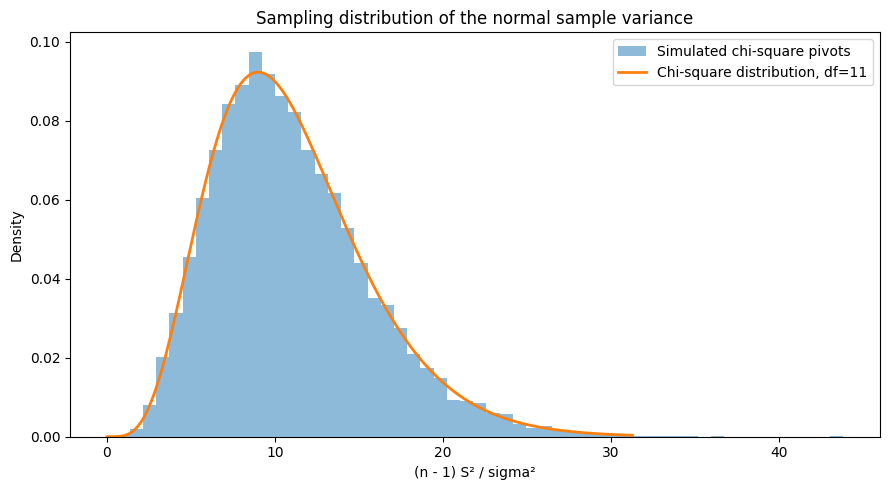

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

rng = np.random.default_rng(2026)

n = 12
mu = 100.0
sigma = 5.0
repetitions = 20_000

samples = rng.normal(mu, sigma, size=(repetitions, n))
sample_variances = np.var(samples, axis=1, ddof=1)
pivots = (n - 1) * sample_variances / sigma**2

df = n - 1
print(f"Empirical pivot mean: {pivots.mean():.3f}")
print(f"Theoretical mean:     {df}")
print(f"Empirical pivot variance: {pivots.var(ddof=1):.3f}")
print(f"Theoretical variance:     {2 * df}")

x = np.linspace(0, chi2.ppf(0.999, df), 400)
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(pivots, bins=55, density=True, alpha=0.5,
        label="Simulated chi-square pivots")
ax.plot(x, chi2.pdf(x, df), linewidth=2,
        label=f"Chi-square distribution, df={df}")
ax.set_xlabel("(n - 1) S² / sigma²")
ax.set_ylabel("Density")
ax.set_title("Sampling distribution of the normal sample variance")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/one_variance_chi_square_sampling.png", dpi=180,
            bbox_inches="tight")
plt.show()

# Experiment: increase n and compare the simulated distribution.

##  Experiment: calculating variance-test p-values and critical values.

In [2]:
from scipy.stats import chi2

n = 20
sample_sd = 6.1
sigma_0 = 4.0
alpha = 0.05
df = n - 1

statistic = df * sample_sd**2 / sigma_0**2
p_left = chi2.cdf(statistic, df)
p_right = chi2.sf(statistic, df)
p_two_sided = min(1.0, 2 * min(p_left, p_right))

lower_critical = chi2.ppf(alpha / 2, df)
upper_critical = chi2.isf(alpha / 2, df)

print(f"Statistic: {statistic:.5f}")
print(f"Left-tailed p-value:  {p_left:.6f}")
print(f"Right-tailed p-value: {p_right:.6f}")
print(f"Two-sided p-value:   {p_two_sided:.6f}")
print(f"Two-sided critical values: {lower_critical:.3f}, "
      f"{upper_critical:.3f}")
print("Reject right-sided H0:", p_right < alpha)

# Experiment: change the sample SD while keeping n fixed.

Statistic: 44.18687
Left-tailed p-value:  0.999110
Right-tailed p-value: 0.000890
Two-sided p-value:   0.001779
Two-sided critical values: 8.907, 32.852
Reject right-sided H0: True


## Experiment: exact confidence intervals for variance and standard deviation.

In [3]:
import numpy as np
from scipy.stats import chi2

n = 20
s = 6.1
alpha = 0.05
df = n - 1

q_lower = chi2.ppf(alpha / 2, df)
q_upper = chi2.ppf(1 - alpha / 2, df)

variance_ci = (
    df * s**2 / q_upper,
    df * s**2 / q_lower
)
sd_ci = tuple(np.sqrt(variance_ci))

print(f"Sample variance: {s**2:.4f}")
print(f"95% CI for variance: {variance_ci}")
print(f"95% CI for SD:       {sd_ci}")

# Verify the connection with the two-sided test.
sigma_0 = 4.0
statistic = df * s**2 / sigma_0**2
p_value = min(1.0, 2 * min(
    chi2.cdf(statistic, df),
    chi2.sf(statistic, df)
))
excluded = not (sd_ci[0] <= sigma_0 <= sd_ci[1])

print(f"Two-sided p-value: {p_value:.6f}")
print("Null excluded by interval:", excluded)

# Experiment: compare 90%, 95%, and 99% intervals.

Sample variance: 37.2100
95% CI for variance: (21.520241259488568, 79.37895825262054)
95% CI for SD:       (4.638991405412233, 8.909486980327236)
Two-sided p-value: 0.001779
Null excluded by interval: True


## Experiment: confidence-interval coverage and sensitivity to nonnormality.

Normal: CI coverage = 95.030%, type I error = 4.970%
Exponential: CI coverage = 71.890%, type I error = 28.110%


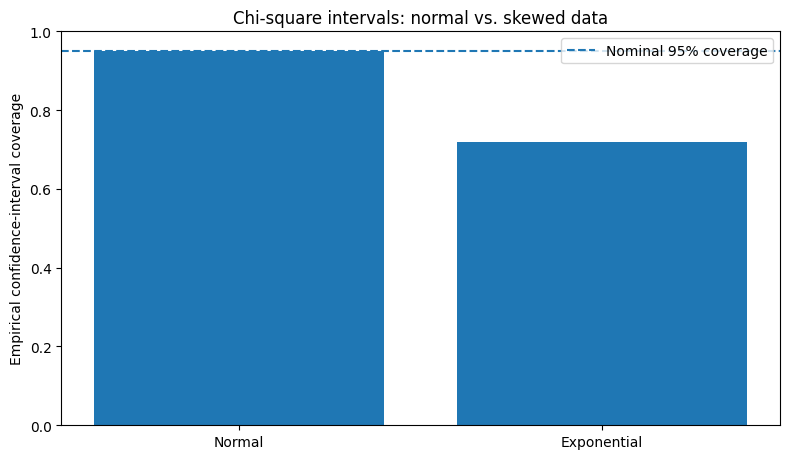

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

rng = np.random.default_rng(2026)

n = 30
repetitions = 10_000
sigma = 10.0
alpha = 0.05
df = n - 1

# Both populations have true SD = 10, but different shapes.
normal = rng.normal(0, sigma, size=(repetitions, n))
skewed = rng.exponential(scale=sigma, size=(repetitions, n))

q_lower = chi2.ppf(alpha / 2, df)
q_upper = chi2.isf(alpha / 2, df)

coverages = {}
rejection_rates = {}

for name, samples in [("Normal", normal), ("Exponential", skewed)]:
    s2 = np.var(samples, axis=1, ddof=1)
    lower = df * s2 / q_upper
    upper = df * s2 / q_lower
    coverage = np.mean((lower <= sigma**2) &
                       (sigma**2 <= upper))

    pivot_under_null = df * s2 / sigma**2
    rejects = ((pivot_under_null < q_lower) |
               (pivot_under_null > q_upper))

    coverages[name] = coverage
    rejection_rates[name] = rejects.mean()
    print(f"{name}: CI coverage = {coverage:.3%}, "
          f"type I error = {rejects.mean():.3%}")

fig, ax = plt.subplots(figsize=(8, 4.7))
ax.bar(list(coverages), list(coverages.values()))
ax.axhline(0.95, linestyle="--", label="Nominal 95% coverage")
ax.set_ylim(0, 1)
ax.set_ylabel("Empirical confidence-interval coverage")
ax.set_title("Chi-square intervals: normal vs. skewed data")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/one_variance_coverage_nonnormal.png", dpi=180,
            bbox_inches="tight")
plt.show()

# Experiment: repeat for n=10 and n=200.

##  Experiment: normal Q-Q plots for different distribution shapes.

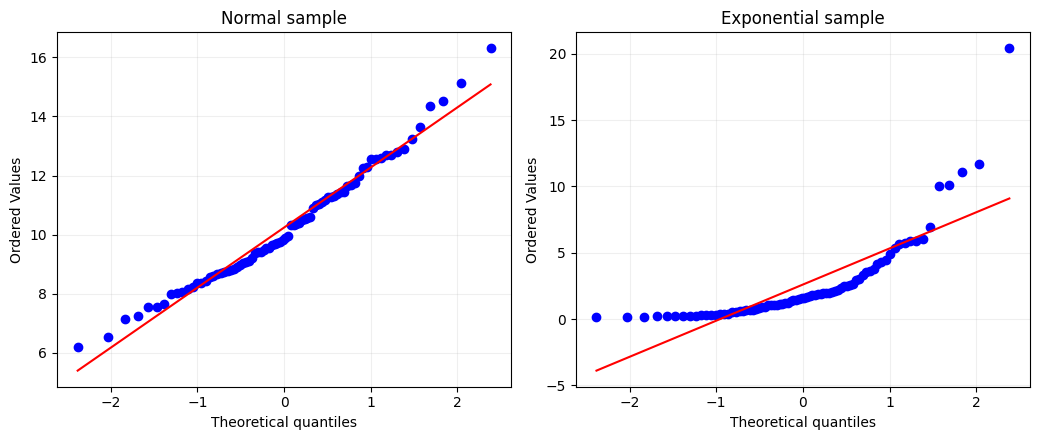

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)

normal_sample = rng.normal(loc=10, scale=2, size=80)
skewed_sample = rng.exponential(scale=2, size=80)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5))

for ax, (name, sample) in zip(axes, [
    ("Normal sample", normal_sample),
    ("Exponential sample", skewed_sample)
]):
    stats.probplot(sample, dist="norm", plot=ax)
    ax.set_title(name)
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig("../../images/one_variance_normality_qq.png", dpi=180,
            bbox_inches="tight")
plt.show()

# Experiment: repeat with a smaller sample of 15 observations.
# Can a small sample hide departures from normality?

## Experiment: power and sample size for the variance test.

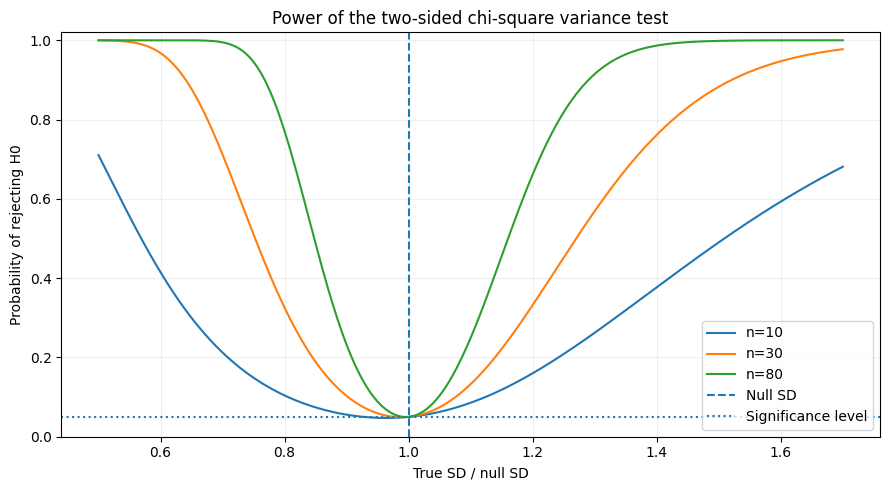

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

alpha = 0.05
sample_sizes = [10, 30, 80]
sd_ratios = np.linspace(0.5, 1.7, 300)

fig, ax = plt.subplots(figsize=(9, 5))

for n in sample_sizes:
    df = n - 1
    lower_critical = chi2.ppf(alpha / 2, df)
    upper_critical = chi2.isf(alpha / 2, df)

    # Each ratio is sigma_true / sigma_null.
    powers = (
        chi2.cdf(lower_critical / sd_ratios**2, df)
        + chi2.sf(upper_critical / sd_ratios**2, df)
    )

    ax.plot(sd_ratios, powers, label=f"n={n}")

ax.axvline(1.0, linestyle="--", label="Null SD")
ax.axhline(alpha, linestyle=":", label="Significance level")
ax.set_ylim(0, 1.02)
ax.set_xlabel("True SD / null SD")
ax.set_ylabel("Probability of rejecting H0")
ax.set_title("Power of the two-sided chi-square variance test")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("../../images/one_variance_power_sample_size.png", dpi=180,
            bbox_inches="tight")
plt.show()

# Experiment: compare alpha=0.01 with alpha=0.05.

## Experiment: student-height variability and a prespecified reference.

Sample size: 30
Sample SD: 9.301 cm
Chi-square statistic: 39.203
Left-sided p-value: 0.9022
95% two-sided CI for SD: [7.408, 12.504] cm
Reject the left-sided null: False


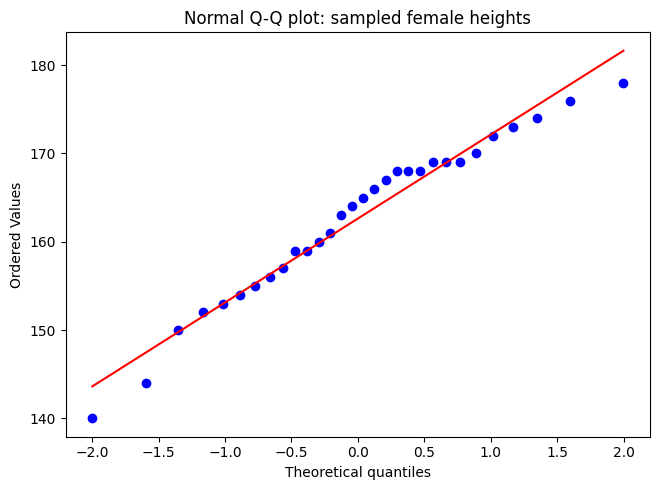

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

students = pd.read_csv(
    "https://userpage.fu-berlin.de/soga/data/raw-data/students.csv"
)

female_heights = students.loc[
    students["gender"].astype(str).str.strip().eq("Female"),
    "height"
].dropna()

# Sample from the available female-student records.
sample = female_heights.sample(n=30, random_state=12).to_numpy()

sigma_0 = 8.0  # Hypothetical, fixed benchmark in centimeters.
alpha = 0.05
n = len(sample)
df = n - 1
s = np.std(sample, ddof=1)

statistic = df * s**2 / sigma_0**2
p_value = stats.chi2.cdf(statistic, df)

sd_lower = s * np.sqrt(df / stats.chi2.isf(alpha / 2, df))
sd_upper = s * np.sqrt(df / stats.chi2.ppf(alpha / 2, df))

print(f"Sample size: {n}")
print(f"Sample SD: {s:.3f} cm")
print(f"Chi-square statistic: {statistic:.3f}")
print(f"Left-sided p-value: {p_value:.4f}")
print(f"95% two-sided CI for SD: [{sd_lower:.3f}, {sd_upper:.3f}] cm")
print("Reject the left-sided null:", p_value < alpha)

fig, ax = plt.subplots(figsize=(6.7, 5))
stats.probplot(sample, dist="norm", plot=ax)
ax.set_title("Normal Q-Q plot: sampled female heights")
fig.tight_layout()
fig.savefig("../../images/one_variance_students_qq.png", dpi=180,
            bbox_inches="tight")
plt.show()

# Interpretation depends on normality and the sampling design.